## HOMEWORK 04- EVALUATION

# DATA PREPARATION

In [3]:
!pip install pandas numpy scikit-learn matplotlib

  Using cached pandas-3.0.6-cp314-cp314-manylinux_2_24_x86_64.manylinux_2_28_x86_64.whl.metadata (79 kB)
  Using cached numpy-2.5.4-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (6.6 kB)
  Using cached scikit_learn-1.9.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (9.3 kB)
  Using cached matplotlib-3.11.2-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (80 kB)
  Using cached scipy-1.18.1-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (62 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached narwhals-2.27.1-py3-none-any.whl.metadata (15 kB)
  Using cached threadpoolctl-3.7.0-py3-none-any.whl.metadata (24 kB)
  Using cached contourpy-1.4.0-cp314-cp314-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp314-cp314-manylinux2014_x86_64.manylinux_2_17_x86_64.whl.me

In [4]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"

df = pd.read_csv(url)

print("Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum())
print("\nFirst 5 rows:")
display(df.head())


Shape: (5000, 9)

Missing values:
lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

First 5 rows:


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [5]:


y = df["converted"]


categorical = df.select_dtypes(include=["object"]).columns
numerical = df.select_dtypes(exclude=["object"]).columns

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0.0)


df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

print("Full train:", df_full_train.shape)
print("Train:", df_train.shape)
print("Validation:", df_val.shape)
print("Test:", df_test.shape)


Full train: (4000, 9)
Train: (3000, 9)
Validation: (1000, 9)
Test: (1000, 9)


/tmp/ipykernel_16944/3292818759.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=["object"]).columns


## Q1- ROC AUC

In [ ]:

from sklearn.metrics import roc_auc_score

# Target aktual dari training dataset
y_train = df_train["converted"]

features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income"
]

for feature in features:
    score = roc_auc_score(y_train, df_train[feature])

    # Jika AUC < 0.5, balik arah skornya
    if score < 0.5:
        score = roc_auc_score(y_train, -df_train[feature])

    print(f"{feature}: {score:.6f}")                         # highest AUC : lead_score 0.713, number_of_courses_viewed 0.701, interaction_count 0.699, annual_income 0.501


lead_score: 0.788225
number_of_courses_viewed: 0.722989
interaction_count: 0.764920
annual_income: 0.608198


## Q2 - LOGISTIC REGRESSION


In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score


df = df.copy()

categorical = df.select_dtypes(include="object").columns
numerical = df.select_dtypes(exclude="object").columns

df[categorical] = df[categorical].fillna("NA")
df[numerical] = df[numerical].fillna(0)


df_full_train, df_test = train_test_split(
    df, test_size=0.2, random_state=1
)

df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)


y_train = df_train["converted"].values
y_val = df_val["converted"].values

X_train = df_train.drop(columns=["converted"])
X_val = df_val.drop(columns=["converted"])


dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(X_train.to_dict(orient="records"))
X_val = dv.transform(X_val.to_dict(orient="records"))


model = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000
)
model.fit(X_train, y_train)


y_pred = model.predict_proba(X_val)[:, 1]

auc = roc_auc_score(y_val, y_pred)
print("ROC AUC:", round(auc, 3))                         # ROC AUC Logistic Regression : 0.732


ROC AUC: 0.732


/tmp/ipykernel_16944/3573764288.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include="object").columns


## Q3- PRECISSION AND RECALL

Intersection threshold: 0.63
Precision: 0.733
Recall: 0.725


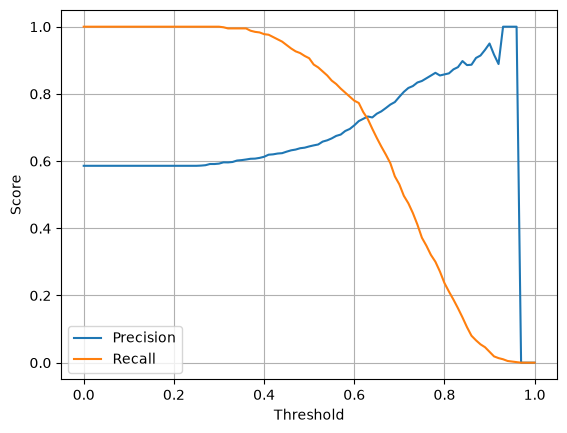

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0.0, 1.01, 0.01)

precisions = []
recalls = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)

    p = precision_score(y_val, y_pred_binary, zero_division=0)
    r = recall_score(y_val, y_pred_binary, zero_division=0)

    precisions.append(p)
    recalls.append(r)

precisions = np.array(precisions)
recalls = np.array(recalls)

# Abaikan threshold saat precision dan recall sama-sama nol
valid = (precisions != 0) | (recalls != 0)
differences = np.abs(precisions - recalls)
differences[~valid] = np.inf

best_idx = np.argmin(differences)

print("Intersection threshold:", thresholds[best_idx])
print("Precision:", round(precisions[best_idx], 3))
print("Recall:", round(recalls[best_idx], 3))

plt.plot(thresholds, precisions, label="Precision")
plt.plot(thresholds, recalls, label="Recall")
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.legend()
plt.grid()
plt.show()                                # The threshold where precision and recall intersect : 0.63


## Q4- F1 SCORE

In [ ]:

from sklearn.metrics import f1_score

f1_scores = []

for t in thresholds:
    y_pred_binary = (y_pred >= t).astype(int)
    f1 = f1_score(y_val, y_pred_binary, zero_division=0)
    f1_scores.append(f1)

best_idx = np.argmax(f1_scores)

print("Best threshold:", round(thresholds[best_idx], 2))
print("Best F1 score:", round(f1_scores[best_idx], 3))      # HIGHEST F1 threshold : 0.41


Best threshold: 0.41
Best F1 score: 0.758


## Q5- 5-FOLD CROSS VALIDATION

In [ ]:

from sklearn.model_selection import KFold
from sklearn.metrics import roc_auc_score
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
import numpy as np

df_full_train = df_full_train.reset_index(drop=True)

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train_fold = df_full_train.iloc[train_idx]
    df_val_fold = df_full_train.iloc[val_idx]

    y_train_fold = df_train_fold["converted"].values
    y_val_fold = df_val_fold["converted"].values

    X_train_fold = df_train_fold.drop(columns=["converted"])
    X_val_fold = df_val_fold.drop(columns=["converted"])

    dv_fold = DictVectorizer(sparse=False)
    X_train_encoded = dv_fold.fit_transform(
        X_train_fold.to_dict(orient="records")
    )
    X_val_encoded = dv_fold.transform(
        X_val_fold.to_dict(orient="records")
    )

    model_fold = LogisticRegression(
        solver="liblinear", C=1.0, max_iter=1000
    )
    model_fold.fit(X_train_encoded, y_train_fold)

    y_pred_fold = model_fold.predict_proba(X_val_encoded)[:, 1]
    auc_fold = roc_auc_score(y_val_fold, y_pred_fold)
    scores.append(auc_fold)

print("Scores:", scores)
print("Mean AUC:", round(np.mean(scores), 3))
print("Standard deviation:", round(np.std(scores), 3)) # standar deviation 5-FOLD  AUC : 0.007


Scores: [0.7305601027122453, 0.7295726148196622, 0.7363428071259397, 0.7412454717957564, 0.7209138590326581]
Mean AUC: 0.732
Standard deviation: 0.007


## Q6- HYPERPARAMTER TUNING

In [ ]:

from sklearn.model_selection import KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
results = {}

for C in [0.000001, 0.001, 1]:
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        train_fold = df_full_train.iloc[train_idx]
        val_fold = df_full_train.iloc[val_idx]

        y_train_fold = train_fold["converted"].values
        y_val_fold = val_fold["converted"].values

        X_train_fold = train_fold.drop(columns=["converted"])
        X_val_fold = val_fold.drop(columns=["converted"])

        dv = DictVectorizer(sparse=False)
        X_train_enc = dv.fit_transform(
            X_train_fold.to_dict(orient="records")
        )
        X_val_enc = dv.transform(
            X_val_fold.to_dict(orient="records")
        )

        model = LogisticRegression(
            solver="liblinear", C=C, max_iter=1000
        )
        model.fit(X_train_enc, y_train_fold)

        y_pred_fold = model.predict_proba(X_val_enc)[:, 1]
        scores.append(roc_auc_score(y_val_fold, y_pred_fold))

    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    results[C] = (mean_auc, std_auc)

    print(
        f"C={C}: mean AUC={mean_auc:.3f}, "
        f"std={std_auc:.3f}"
    )

best_C = max(
    results,
    key=lambda c: (round(results[c][0], 3),
                   -round(results[c][1], 3),
                   -c)
)

print("\nBest C:", best_C)                # c: 0.001


C=1e-06: mean AUC=0.617, std=0.019
C=0.001: mean AUC=0.749, std=0.010
C=1: mean AUC=0.732, std=0.007

Best C: 0.001
